## 1) Imports and Configuration


In [ ]:
import os
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
)

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
import kagglehub


##2) Dataset Download and Initial Setup

In this step, the Professional Depression Dataset is downloaded directly from Kaggle using the `kagglehub` library.  
This ensures reproducibility and avoids manual file handling.


In [ ]:
!pip -q install kagglehub[pandas-datasets]

In [ ]:
dataset_path = kagglehub.dataset_download(
    "aizahzeeshan/professional-depression-dataset"
)

dataset_path

100%|██████████| 15.5k/15.5k [00:00<00:00, 8.49MB/s]

Extracting files...


'/root/.cache/kagglehub/datasets/aizahzeeshan/professional-depression-dataset/versions/1'

In [ ]:
os.listdir(dataset_path)

['Depression Professional Dataset.csv']

##3) Preview the Dataset

The first few rows of the dataset were displayed  to understand its structure and available features.


In [ ]:
CSV_NAME = "Depression Professional Dataset.csv"

csv_path = os.path.join(dataset_path, CSV_NAME)
df = pd.read_csv(csv_path)

df.head()

,Gender,Age,Work Pressure,Job Satisfaction,Sleep Duration,Dietary Habits,Have you ever had suicidal thoughts ?,Work Hours,Financial Stress,Family History of Mental Illness,Depression
0,Female,37,2.0,4.0,7-8 hours,Moderate,No,6,2,No,No
1,Male,60,4.0,3.0,5-6 hours,Unhealthy,Yes,0,4,Yes,No
2,Female,42,2.0,3.0,5-6 hours,Moderate,No,0,2,No,No
3,Female,44,3.0,5.0,7-8 hours,Healthy,Yes,1,2,Yes,No
4,Male,48,4.0,3.0,7-8 hours,Moderate,Yes,6,5,Yes,No


##4) Dataset Inspection and Understanding

In this section, we explore the dataset to understand its structure, target variable,
feature types, and class distribution before applying any preprocessing or modelling steps.


In [ ]:
print("Dataset shape:", df.shape)

df.info()

categorical_features = df.select_dtypes(include=['object']).columns.tolist()
numerical_features = df.select_dtypes(include=['int64', 'float64']).columns.tolist()

print("\nCategorical features:", categorical_features)
print("\nNumerical features:", numerical_features)


Dataset shape: (2054, 11)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2054 entries, 0 to 2053
Data columns (total 11 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   Gender                                 2054 non-null   object 
 1   Age                                    2054 non-null   int64  
 2   Work Pressure                          2054 non-null   float64
 3   Job Satisfaction                       2054 non-null   float64
 4   Sleep Duration                         2054 non-null   object 
 5   Dietary Habits                         2054 non-null   object 
 6   Have you ever had suicidal thoughts ?  2054 non-null   object 
 7   Work Hours                             2054 non-null   int64  
 8   Financial Stress                       2054 non-null   int64  
 9   Family History of Mental Illness       2054 non-null   object 
 10  Depression                             2054 no

Depression
No     1851
Yes     203
Name: count, dtype: int64


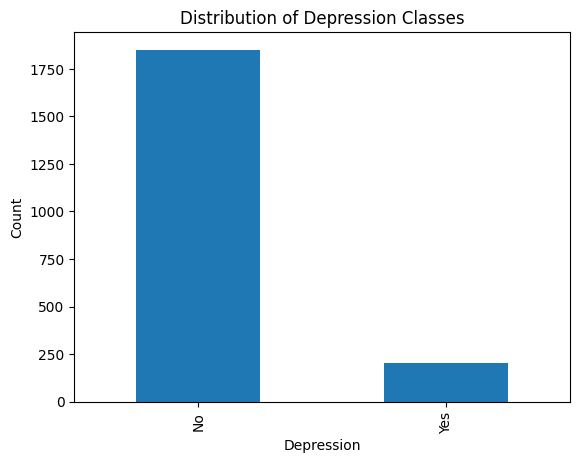

In [ ]:
target_counts = df['Depression'].value_counts()
print(target_counts)

target_counts.plot(kind='bar')
plt.title('Distribution of Depression Classes')
plt.xlabel('Depression')
plt.ylabel('Count')
plt.show()


##5) Data Quality Checks

This section examines potential data quality issues such as missing values and duplicate records
to ensure the reliability of the dataset before modelling.


In [ ]:
missing_values = df.isna().sum()
print("Missing values per feature:\n", missing_values[missing_values > 0])

duplicate_count = df.duplicated().sum()
print("\nNumber of duplicate rows:", duplicate_count)

Missing values per feature:
 Series([], dtype: int64)

Number of duplicate rows: 0


##6) Exploratory Data Analysis (EDA)

This section explores the relationship between selected features and depression status
to identify patterns and potential risk factors beyond simple classification.


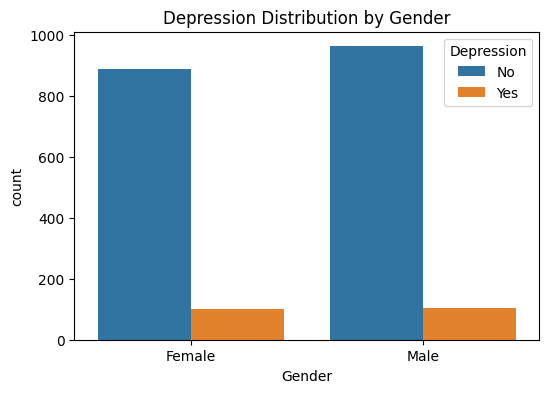

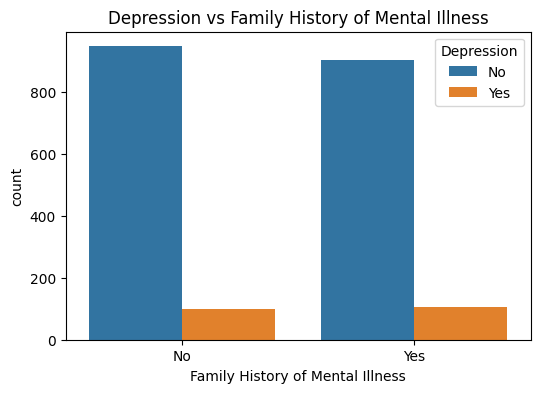

In [ ]:
plt.figure(figsize=(6,4))
sns.countplot(data=df, x='Gender', hue='Depression')
plt.title('Depression Distribution by Gender')
plt.show()

plt.figure(figsize=(6,4))
sns.countplot(data=df, x='Family History of Mental Illness', hue='Depression')
plt.title('Depression vs Family History of Mental Illness')
plt.show()


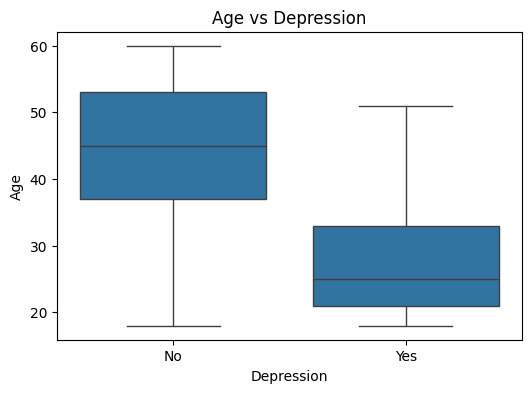

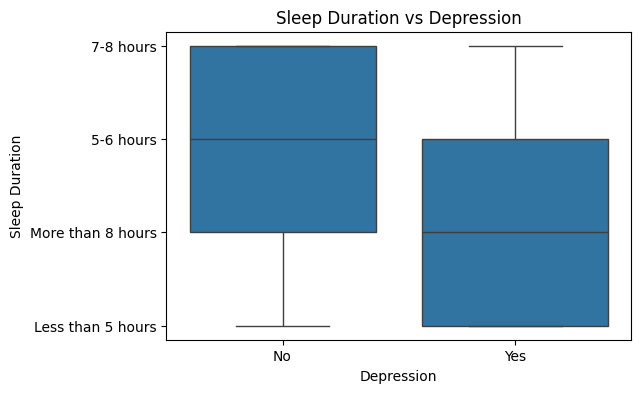

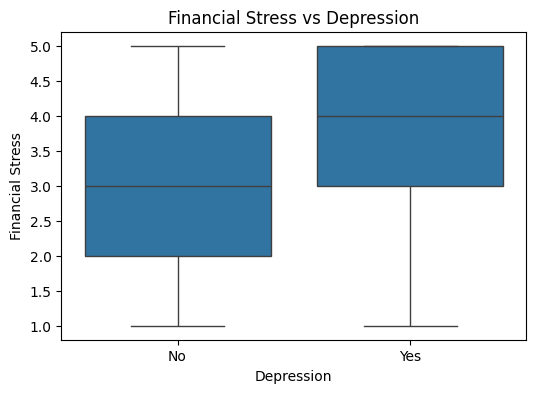

In [ ]:
numerical_to_plot = ['Age', 'Sleep Duration', 'Financial Stress']

for feature in numerical_to_plot:
    plt.figure(figsize=(6,4))
    sns.boxplot(data=df, x='Depression', y=feature)
    plt.title(f'{feature} vs Depression')
    plt.show()


##7) Feature Preparation and Train–Test Split

In this step, categorical features are encoded, numerical features are scaled,
and the dataset is split into training and testing sets in preparation for classification models.


In [ ]:
TARGET_COLUMN = 'Depression'

X = df.drop(columns=[TARGET_COLUMN])
y = df[TARGET_COLUMN]

categorical_features = [
    c for c in categorical_features if c != TARGET_COLUMN
]

numerical_features = [
    c for c in numerical_features if c != TARGET_COLUMN
]

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), categorical_features)
    ]
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

X_train.shape, X_test.shape

((1643, 10), (411, 10))

## 8) Evaluation Helper Function


In [ ]:
def evaluate_model(model, X_test, y_test, pos_label="Yes"):
    y_pred = model.predict(X_test)

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, pos_label=pos_label)
    rec = recall_score(y_test, y_pred, pos_label=pos_label)
    f1 = f1_score(y_test, y_pred, pos_label=pos_label)
    cm = confusion_matrix(y_test, y_pred)

    return {
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1": f1,
        "ConfusionMatrix": cm
    }


## 9) Train and Compare Models
- Logistic Regression
- Random Forest
- Gradient Boosting


In [ ]:
models = {
    "Logistic Regression": Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(max_iter=2000))
    ]),
    "Random Forest": Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(n_estimators=400, random_state=42))
    ]),
    "HistGradientBoosting": Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", HistGradientBoostingClassifier(random_state=42))
    ]),
}

results = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    results[name] = evaluate_model(model, X_test, y_test, pos_label="Yes")
    print(f"\n{name}")
    print("Accuracy:", results[name]["Accuracy"])
    print("Precision:", results[name]["Precision"])
    print("Recall:", results[name]["Recall"])
    print("F1:", results[name]["F1"])
    print("Confusion Matrix:\n", results[name]["ConfusionMatrix"])



Logistic Regression
Accuracy: 0.9878345498783455
Precision: 1.0
Recall: 0.8780487804878049
F1: 0.935064935064935
Confusion Matrix:
 [[370   0]
 [  5  36]]

Random Forest
Accuracy: 0.948905109489051
Precision: 1.0
Recall: 0.4878048780487805
F1: 0.6557377049180327
Confusion Matrix:
 [[370   0]
 [ 21  20]]

HistGradientBoosting
Accuracy: 0.9708029197080292
Precision: 0.967741935483871
Recall: 0.7317073170731707
F1: 0.8333333333333334
Confusion Matrix:
 [[369   1]
 [ 11  30]]


In [ ]:
comparison_df = pd.DataFrame([
    {"Model": name,
     "Accuracy": res["Accuracy"],
     "Precision": res["Precision"],
     "Recall": res["Recall"],
     "F1": res["F1"]}
    for name, res in results.items()
]).sort_values(by="F1", ascending=False)

comparison_df


,Model,Accuracy,Precision,Recall,F1
0,Logistic Regression,0.987835,1.000000,0.878049,0.935065
2,HistGradientBoosting,0.970803,0.967742,0.731707,0.833333
1,Random Forest,0.948905,1.000000,0.487805,0.655738


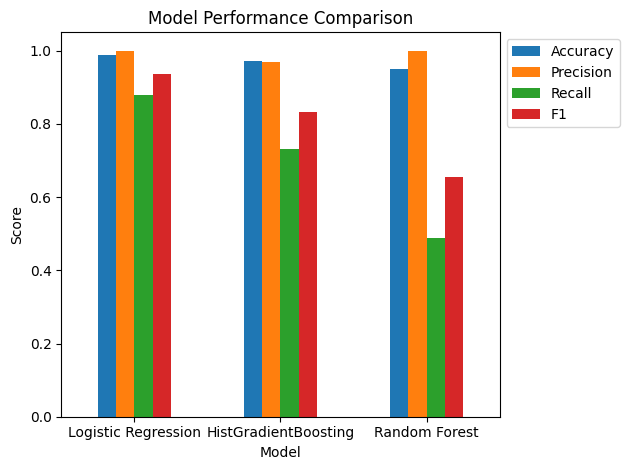

In [ ]:
df_plot = comparison_df.set_index("Model")

ax = df_plot.plot(kind="bar")

plt.legend(
    bbox_to_anchor=(1,1),
    frameon=True
)

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Model")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


##10) Model Selection and Risk Stratification

Three classification models were evaluated using accuracy, precision, recall, and F1-score.
Logistic Regression demonstrated the most balanced performance across these metrics,
particularly achieving higher recall while maintaining perfect precision.
Given the importance of reliably identifying depression cases, Logistic Regression
was selected as the final model, and risk stratification was performed using this model.


In [ ]:
best_model_name = "Logistic Regression"
best_model = models[best_model_name]

best_prob = best_model.predict_proba(X_test)[:, 1]

def risk_group(p):
    if p < 0.33:
        return "Low"
    elif p < 0.66:
        return "Medium"
    else:
        return "High"

risk_groups = pd.Series(best_prob).apply(risk_group)

risk_counts = risk_groups.value_counts().reindex(["Low", "Medium", "High"]).fillna(0).astype(int)
risk_counts


,count
Low,362
Medium,16
High,33


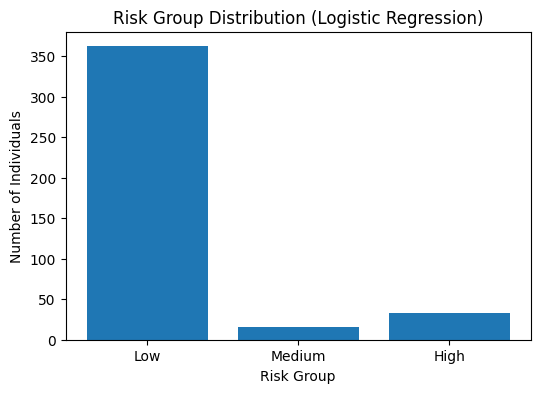

In [ ]:
plt.figure(figsize=(6,4))
plt.bar(risk_counts.index, risk_counts.values)
plt.title(f"Risk Group Distribution ({best_model_name})")
plt.xlabel("Risk Group")
plt.ylabel("Number of Individuals")
plt.show()


In [ ]:
risk_df = pd.DataFrame({
    "Risk_Group": risk_groups.values,
    "True_Depression": y_test.values
})

risk_yes = (
    risk_df
    .groupby("Risk_Group")["True_Depression"]
    .apply(lambda s: (s == "Yes").mean())
    .reindex(["Low", "Medium", "High"])
    .fillna(0)
    .reset_index(name="Proportion_Yes")
)

risk_yes


,Risk_Group,Proportion_Yes
0,Low,0.0
1,Medium,0.5
2,High,1.0


##11) Risk Plot
This plot visualises the proportion of true depression cases in each risk group.


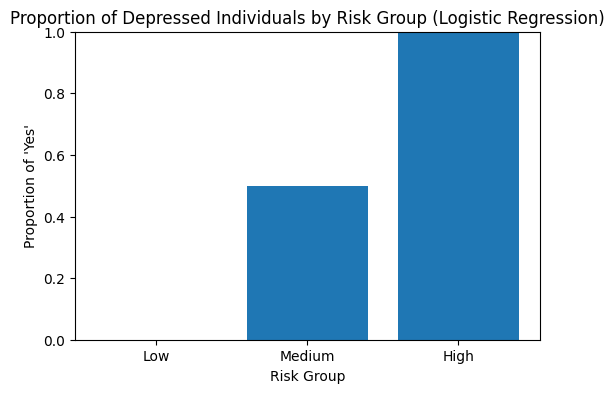

In [ ]:
plt.figure(figsize=(6,4))
plt.bar(risk_yes["Risk_Group"], risk_yes["Proportion_Yes"])
plt.title(f"Proportion of Depressed Individuals by Risk Group ({best_model_name})")
plt.xlabel("Risk Group")
plt.ylabel("Proportion of 'Yes'")
plt.ylim(0, 1)
plt.show()


##12) Interpretation
For interpretability, Logistic Regression coefficients can be analysed.

In [ ]:
lr_model = models["Logistic Regression"]

feature_names = lr_model.named_steps["preprocessor"].get_feature_names_out()
coef = lr_model.named_steps["classifier"].coef_[0]

fi = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coef,
    "Abs": np.abs(coef)
}).sort_values("Abs", ascending=False)

fi["Feature"] = (
    fi["Feature"]
    .str.replace("cat__", "", regex=False)
    .str.replace("num__", "", regex=False)
)

fi.head(10)


,Feature,Coefficient,Abs
11,Have you ever had suicidal thoughts ?_Yes,5.038675,5.038675
0,Age,-4.262707,4.262707
1,Work Pressure,2.155274,2.155274
2,Job Satisfaction,-2.099741,2.099741
10,Dietary Habits_Unhealthy,1.866196,1.866196
4,Financial Stress,1.703106,1.703106
3,Work Hours,1.382906,1.382906
12,Family History of Mental Illness_Yes,1.299534,1.299534
8,Sleep Duration_More than 8 hours,-1.223875,1.223875
6,Sleep Duration_7-8 hours,-0.832911,0.832911


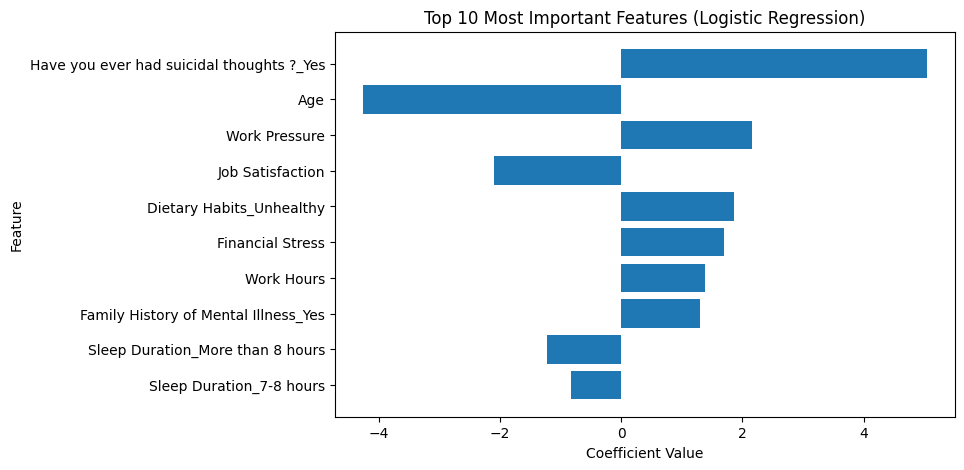

In [ ]:
top_fi = fi.head(10)

plt.figure(figsize=(8,5))
plt.barh(
    top_fi["Feature"],
    top_fi["Coefficient"]
)

plt.xlabel("Coefficient Value")
plt.ylabel("Feature")
plt.title("Top 10 Most Important Features (Logistic Regression)")
plt.gca().invert_yaxis()
plt.show()
